# Compare abundance z-scores from different assays

In [ ]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [12]:
dualipa_outputs = "../../2_individual_assay_results/dual_ipa/3_outputs"
imaging_outputs = "../../2_individual_assay_results/imaging/3_outputs"

dualipa = pd.read_table(f"{dualipa_outputs}/DUALIPA_median_zscore.tsv")
imaging = pl.read_csv(f"{imaging_outputs}/abundance/abundance_ttest_stats.csv")



In [13]:
# process dualipa
dualipa = pl.DataFrame(dualipa).with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("Variant")
)

dualipa = dualipa.select(["Variant", "zscore_log2", "zscore_median", "median_gfp"]).rename({
    "zscore_log2": "dualipa_zscore_log2",
    "zscore_median": "dualipa_zscore"
})

# get imaging abundance measures
imaging = imaging.select([
    "Variant", "U2OS_t"
]).rename({
    "U2OS_t": "imaging_zscore"
}).filter(pl.col("imaging_zscore") > -100) # there is one major outlier

# merge
abun_df = dualipa.join(imaging, on="Variant").filter(~pl.col("dualipa_zscore").is_null()).filter(~pl.col("imaging_zscore").is_null()).to_pandas()
print(abun_df.shape)

(776, 5)


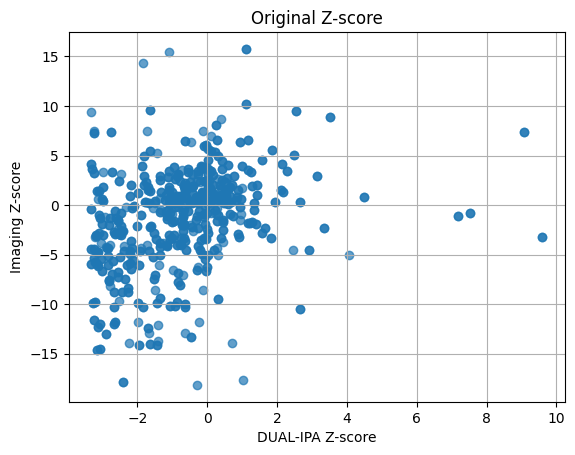

In [14]:
plt.scatter(abun_df['dualipa_zscore'], abun_df['imaging_zscore'], alpha=0.7)
plt.ylabel('Imaging Z-score')
plt.xlabel('DUAL-IPA Z-score')
plt.title('Original Z-score')
plt.grid(True)
plt.show()

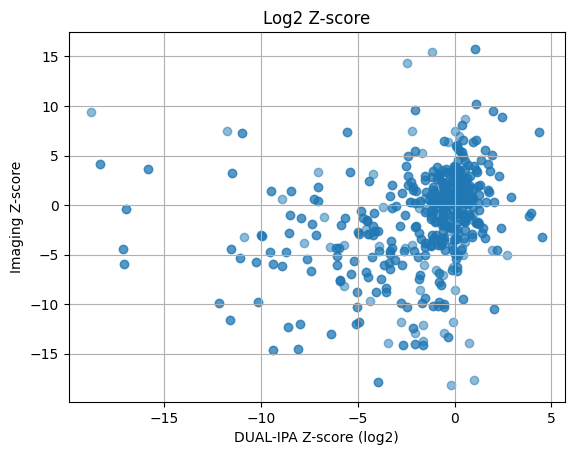

In [19]:
plt.scatter(abun_df['dualipa_zscore_log2'], abun_df['imaging_zscore'], alpha=0.5)
plt.ylabel('Imaging Z-score')
plt.xlabel('DUAL-IPA Z-score (log2)')
plt.title('Log2 Z-score')
plt.grid(True)
plt.show()

In [18]:
# Compute Pearson correlation coefficient and p-value
corr, p_value = pearsonr(abun_df['dualipa_zscore_log2'], abun_df['imaging_zscore'])

print(f"Pearson correlation: {corr:.3f}")
print(f"P-value: {p_value:.3e}")

Pearson correlation: 0.272
P-value: 1.275e-14
